# Walmart Store Sales — EDA and Sales Forecasting
**RVCE Applied Data Science Skill Lab — Mini-Project**

**Workflow:** Problem → Data → Analysis → Evidence → Insight → Conclusion

---
## 1. Problem Identification
**Problem statement:** Walmart runs 45 stores and sells very different amounts each week. Sales jump around holidays, change with seasons, and differ a lot from store to store. A manager who can't see these patterns can't plan stock or staff.

**Objectives**
1. Understand what the data contains and clean it properly.
2. Find the main patterns: store differences, seasonality, holiday effect, and the role of temperature, fuel price, CPI and unemployment.
3. Check outliers *before* deciding what to do with them.
4. Build a simple, leakage-free model that forecasts a store's next-week sales and measure how good it is.

**Analytical questions**
- Which stores sell the most / least, and how stable are their sales?
- Do holiday weeks really sell more? Which holidays?
- Is there a yearly (seasonal) pattern?
- Do temperature, fuel price, CPI or unemployment relate to sales?

**Intended application:** inventory planning, staffing and promotion timing at store level.

## 2. Data Acquisition

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
RANDOM_STATE = 42

# ---- Paths: change DATA_PATH if your CSV lives somewhere else ----
DATA_PATH = 'Walmart.csv'
OUT_DIR = 'outputs'
FIG_DIR = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), bbox_inches='tight')
    plt.show()

In [2]:
raw = pd.read_csv(DATA_PATH)          # original file is never modified
df = raw.copy()                       # all work happens on the copy
print('Shape:', raw.shape)
raw.head()

Shape: (6435, 8)


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1889275.29,0,26.24,2.301,126.984306,10.738
1,1,12-02-2010,2282834.27,1,31.95,2.271,130.567803,9.441
2,1,19-02-2010,1951324.39,0,27.42,2.565,125.473190,9.281
3,1,26-02-2010,2035811.13,0,41.49,2.658,132.569564,10.692
4,1,05-03-2010,2039019.92,0,44.26,2.307,134.295438,9.738


**Dataset documentation**

| Item | Detail |
|---|---|
| Name | Walmart Store Sales (`Walmart.csv`) |
| Source | Kaggle — Walmart sales dataset (derived from the Walmart Recruiting store-sales competition data) |
| Granularity | One row per store per week |
| Time period | 5 Feb 2010 – 26 Oct 2012 |

| Column | Meaning | Type |
|---|---|---|
| Store | Store number (1–45) | categorical (ID) |
| Date | Week-ending date of the sales week | date |
| Weekly_Sales | Total sales for that store that week (US$) | numeric — **target** |
| Holiday_Flag | 1 if the week contains a special holiday, else 0 | binary |
| Temperature | Average temperature in the region (°F) | numeric |
| Fuel_Price | Regional fuel price (US$/gallon) | numeric |
| CPI | Consumer Price Index (general price level) | numeric |
| Unemployment | Regional unemployment rate (%) | numeric |

**Limitations:** no department/product detail, no promotion (markdown) data, no store size or type, and the data is only ~2.7 years, so yearly patterns are seen only 2–3 times. Public data, no personal information.

## 3. Data Preparation
### 3.1 Data understanding

In [3]:
df.info()
print()
print('Unique stores :', df['Store'].nunique())
print('Missing values:\n', df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   str    
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), str(1)
memory usage: 402.3 KB

Unique stores : 45
Missing values:
 Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64
Duplicate rows: 0


### 3.2 Cleaning and consistency checks

In [4]:
# Dates are written day-first (05-02-2010 = 5 Feb 2010)
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
df = df.sort_values(['Store', 'Date']).reset_index(drop=True)

checks = {
    'Missing values (total)'            : int(df.isna().sum().sum()),
    'Fully duplicated rows'             : int(df.duplicated().sum()),
    'Duplicate Store+Date pairs'        : int(df.duplicated(['Store', 'Date']).sum()),
    'Negative or zero Weekly_Sales'     : int((df['Weekly_Sales'] <= 0).sum()),
    'Holiday_Flag values outside 0/1'   : int((~df['Holiday_Flag'].isin([0, 1])).sum()),
    'Unemployment outside 0-30 %'       : int((~df['Unemployment'].between(0, 30)).sum()),
    'Distinct weeks'                    : df['Date'].nunique(),
    'Weeks per store (min / max)'       : f"{df.groupby('Store').size().min()} / {df.groupby('Store').size().max()}",
}
pd.Series(checks, name='check result').to_frame()

,check result
Missing values (total),0
Fully duplicated rows,0
Duplicate Store+Date pairs,0
Negative or zero Weekly_Sales,0
Holiday_Flag values outside 0/1,0
Unemployment outside 0-30 %,0
Distinct weeks,143
Weeks per store (min / max),143 / 143


In [5]:
# Is the weekly spacing regular (every 7 days)?
gaps = df.groupby('Store')['Date'].diff().dropna().dt.days.value_counts()
print('Gaps between consecutive weeks (days):'); print(gaps)

Gaps between consecutive weeks (days):
Date
7    6390
Name: count, dtype: int64


### 3.3 Derived variables

In [6]:
df['Year']    = df['Date'].dt.year
df['Month']   = df['Date'].dt.month
df['Quarter'] = df['Date'].dt.quarter
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)
df['Temp_C']  = ((df['Temperature'] - 32) * 5 / 9).round(2)   # easier to interpret

# Name the holiday using the official holiday weeks listed with the original dataset
holiday_weeks = {
    'Super Bowl'  : ['2010-02-12', '2011-02-11', '2012-02-10'],
    'Labor Day'   : ['2010-09-10', '2011-09-09', '2012-09-07'],
    'Thanksgiving': ['2010-11-26', '2011-11-25'],
    'Christmas'   : ['2010-12-31', '2011-12-30'],
}
lookup = {pd.Timestamp(d): name for name, ds in holiday_weeks.items() for d in ds}
df['Holiday_Name'] = df['Date'].map(lookup).fillna('None')

# Sanity check: our names must agree with the Holiday_Flag already in the data
print('Rows where Holiday_Flag and holiday name disagree:',
      int(((df['Holiday_Flag'] == 1) != (df['Holiday_Name'] != 'None')).sum()))
df[['Store','Date','Weekly_Sales','Holiday_Flag','Holiday_Name','Year','Month','Temp_C']].head()

Rows where Holiday_Flag and holiday name disagree: 0


,Store,Date,Weekly_Sales,Holiday_Flag,Holiday_Name,Year,Month,Temp_C
0,1,2010-02-05,1889275.29,0,None,2010,2,-3.20
1,1,2010-02-12,2282834.27,1,Super Bowl,2010,2,-0.03
2,1,2010-02-19,1951324.39,0,None,2010,2,-2.54
3,1,2010-02-26,2035811.13,0,None,2010,2,5.27
4,1,2010-03-05,2039019.92,0,None,2010,3,6.81


In [7]:
# Save the cleaned/processed dataset (original Walmart.csv stays untouched)
df.to_csv(os.path.join(OUT_DIR, 'walmart_cleaned.csv'), index=False)
print('Saved cleaned data:', df.shape)

Saved cleaned data: (6435, 14)


**What we found and decided**
- The dataset is already very clean: **6,435 rows = 45 stores × 143 weeks**, no missing values, no duplicate rows, no duplicate store-week pairs, no zero/negative sales, and every gap between weeks is exactly 7 days.
- Only real "cleaning" needed: converting `Date` from text to a proper date (it is day-first, e.g. `05-02-2010`). **No rows were removed and nothing was imputed.**
- `Holiday_Flag` matches the holiday names we attached (0 disagreements), so the flag can be trusted.
- `Temperature` is in °F (values 15–99), so we added `Temp_C` for easier reading.

## 4. Exploratory Data Analysis
### 4.1 Descriptive statistics

In [8]:
num_cols = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']
stats = df[num_cols].describe().T
stats['median'] = df[num_cols].median()
stats['mode']   = [df[c].mode().iloc[0] for c in num_cols]
stats['skew']   = df[num_cols].skew()
stats = stats[['count','mean','median','mode','std','min','25%','50%','75%','max','skew']]
stats.round(3)

,count,mean,median,mode,std,min,25%,50%,75%,max,skew
Weekly_Sales,6435.0,1108331.600,939944.460,256556.060,636774.315,256556.060,641969.875,939944.460,1442767.950,4217604.090,1.034
Temperature,6435.0,60.643,61.940,77.630,17.319,15.070,46.005,61.940,75.570,99.190,-0.167
Fuel_Price,6435.0,3.097,3.093,2.666,0.377,2.093,2.799,3.093,3.397,4.039,0.010
CPI,6435.0,175.728,175.648,110.597,29.329,110.597,150.597,175.648,200.720,238.872,0.001
Unemployment,6435.0,8.496,8.501,7.115,1.310,4.000,7.592,8.501,9.407,12.755,-0.022


In [9]:
# Frequency tables
print('Holiday_Flag counts:'); print(df['Holiday_Flag'].value_counts().rename({0:'Normal week',1:'Holiday week'}).to_frame('rows'))
print()
print('Holiday names:'); print(df['Holiday_Name'].value_counts().to_frame('rows'))

Holiday_Flag counts:
              rows
Holiday_Flag      
Normal week   5985
Holiday week   450

Holiday names:
              rows
Holiday_Name      
None          5985
Super Bowl     135
Labor Day      135
Thanksgiving    90
Christmas       90


In [10]:
# Store-level summary
store_stats = (df.groupby('Store')['Weekly_Sales']
                 .agg(['mean','median','std','min','max'])
                 .assign(cv=lambda x: x['std']/x['mean'])      # cv = how bumpy sales are relative to size
                 .sort_values('mean', ascending=False))
display(store_stats.round(0).assign(cv=store_stats['cv'].round(3)).head(5))
display(store_stats.round(0).assign(cv=store_stats['cv'].round(3)).tail(5))

,mean,median,std,min,max,cv
Store,,,,,,
2,2656476.0,2558529.0,360475.0,2159025.0,3975631.0,0.136
3,2485090.0,2411566.0,364733.0,1911922.0,4217604.0,0.147
4,2372101.0,2301248.0,330730.0,1738114.0,3657735.0,0.139
1,2215302.0,2150615.0,301308.0,1625830.0,3403685.0,0.136
5,2061311.0,1994152.0,313373.0,1486076.0,3503192.0,0.152


,mean,median,std,min,max,cv
Store,,,,,,
32,395160.0,382021.0,58921.0,280416.0,632500.0,0.149
41,374982.0,364509.0,56304.0,279261.0,581068.0,0.150
38,363703.0,356055.0,50655.0,256556.0,582680.0,0.139
33,353698.0,338041.0,57060.0,267024.0,606645.0,0.161
43,342047.0,328125.0,49669.0,262151.0,559926.0,0.145


**Interpretation**
- Average weekly sales per store are about **US$1.11 M**, but the median is lower (**US$0.94 M**) and skewness is 1.03: a few very big store-weeks pull the average up (like a few billionaires lifting the average salary of a room).
- Stores differ enormously: the best store (**Store 2**, ≈ US$2.66 M/week) sells about **7.8×** the smallest (**Store 43**, ≈ US$0.34 M/week). The top 10 stores make about **42 %** of all sales.
- Yet every store is *equally bumpy relative to its own size*: the coefficient of variation (cv) sits between about 0.13 and 0.17 for all 45 stores. So stores differ mainly in **size**, not in how stable they are.
- Only 450 of 6,435 rows (7 %) are holiday weeks, so any holiday finding rests on a small share of the data.
- (The "mode" of a continuous variable like sales is not meaningful; it is shown only because the guidelines ask for it.)

### 4.2 Outlier detection (IQR) — investigate, don't delete

In [11]:
def iqr_bounds(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - 1.5*i, q3 + 1.5*i

rows = []
for c in num_cols:
    lo, hi = iqr_bounds(df[c])
    n = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append([c, round(lo,2), round(hi,2), n, round(100*n/len(df),2)])
pd.DataFrame(rows, columns=['variable','lower fence','upper fence','# outliers','% of rows'])

,variable,lower fence,upper fence,# outliers,% of rows
0,Weekly_Sales,-559227.24,2643965.06,127,1.97
1,Temperature,1.66,119.92,0,0.00
2,Fuel_Price,1.90,4.29,0,0.00
3,CPI,75.41,275.90,0,0.00
4,Unemployment,4.87,12.13,25,0.39


In [12]:
# Weekly_Sales outliers on the whole data are mostly just 'big stores'.
# A fairer test: is a week unusual compared with THAT store's own normal level?
q1 = df.groupby('Store')['Weekly_Sales'].transform(lambda s: s.quantile(.25))
q3 = df.groupby('Store')['Weekly_Sales'].transform(lambda s: s.quantile(.75))
df['out_hi'] = df['Weekly_Sales'] > q3 + 1.5*(q3 - q1)
df['out_lo'] = df['Weekly_Sales'] < q1 - 1.5*(q3 - q1)
print('Global IQR flags      :', int(((df['Weekly_Sales'] < iqr_bounds(df['Weekly_Sales'])[0]) | (df['Weekly_Sales'] > iqr_bounds(df['Weekly_Sales'])[1])).sum()))
print('Within-store IQR flags:', int((df['out_hi'] | df['out_lo']).sum()), '(high:', int(df['out_hi'].sum()), ', low:', int(df['out_lo'].sum()), ')')
print()
print('Within-store HIGH outliers by holiday name:')
print(df.loc[df['out_hi'], 'Holiday_Name'].value_counts().to_frame('weeks'))
print()
print('Within-store HIGH outliers by month:')
print(df.loc[df['out_hi'], 'Month'].value_counts().sort_index().to_frame('weeks').T)

Global IQR flags      : 127
Within-store IQR flags: 695 (high: 672 , low: 23 )

Within-store HIGH outliers by holiday name:
              weeks
Holiday_Name       
None            405
Thanksgiving     89
Christmas        88
Labor Day        67
Super Bowl       23

Within-store HIGH outliers by month:
Month  2   6   9    11   12
weeks  23   1  67  262  319


In [13]:
# Which stores have the high-sales outliers?
print(df.loc[df['out_hi']].groupby('Store').size().sort_values(ascending=False).head(10).to_frame('outlier weeks').T)
print()
print('Within-store LOW outliers:')
display(df.loc[df['out_lo'], ['Store','Date','Weekly_Sales','Holiday_Name']].sort_values('Weekly_Sales').head(10))

Store          35  23  24  20  37  16  21  28  7   10
outlier weeks  19  18  18  18  18  17  17  17  17  17

Within-store LOW outliers:


,Store,Date,Weekly_Sales,Holiday_Name
5341,38,2011-01-21,256556.06,None
4481,32,2011-01-07,280416.00,None
5917,42,2011-02-18,402499.61,None
5866,42,2010-02-26,405698.69,None
5434,39,2010-02-05,416870.99,None
5135,36,2012-08-03,499271.43,None
4150,30,2010-02-26,572984.60,None
4199,30,2011-02-04,582301.98,None
2724,20,2010-03-26,662951.66,None
2378,17,2011-10-28,667316.34,None


**Investigation (nothing was deleted)**
- On the whole dataset the IQR rule flags **127 weeks (2 %)**, and they all belong to just 10 stores, mostly the biggest ones (Store 2: 47, Store 3: 28, Store 4: 20). That is "big stores being big", not errors.
- Judging each week against **its own store's** normal level flags 672 unusually high weeks and 23 unusually low weeks. **581 of the 672 high weeks fall in November and December**, the rest are mostly September (Labor Day) and February (Super Bowl).
- 405 of the high weeks are **not** marked by `Holiday_Flag`. Many are the pre-Christmas weeks, which the flag misses (see 5.4).
- The lowest weeks shown are mostly in January–February, the quiet period right after the holidays.
- Unemployment has 25 rows outside the fences (up to 12.76 % and down to 4.0 %). These are plausible real rates and are kept.

**Decision:** every flagged value looks like genuine seasonal behaviour, so all are **kept**. Removing them would delete exactly the peak weeks a retailer most needs to plan for.

## 5. Visualization and Insight Generation

### 5.1 Distribution of weekly sales

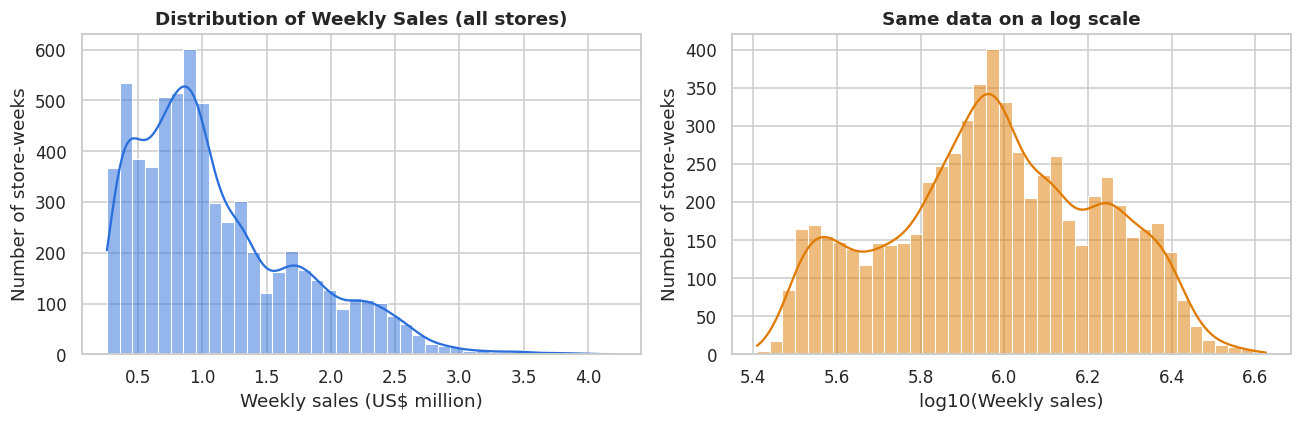

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Weekly_Sales']/1e6, bins=40, kde=True, ax=ax[0], color='#2a6fdb')
ax[0].set(title='Distribution of Weekly Sales (all stores)', xlabel='Weekly sales (US$ million)', ylabel='Number of store-weeks')
sns.histplot(np.log10(df['Weekly_Sales']), bins=40, kde=True, ax=ax[1], color='#e07b00')
ax[1].set(title='Same data on a log scale', xlabel='log10(Weekly sales)', ylabel='Number of store-weeks')
savefig('01_sales_distribution.png')

**Insight:** weekly sales are right-skewed: most store-weeks sit between about US$0.3 M and US$1.5 M with a long tail past US$3 M. On the log scale the shape is closer to symmetric but shows several bumps. That is the signature of **many stores of different sizes mixed together**, so store identity matters for any model.

### 5.2 Store comparison

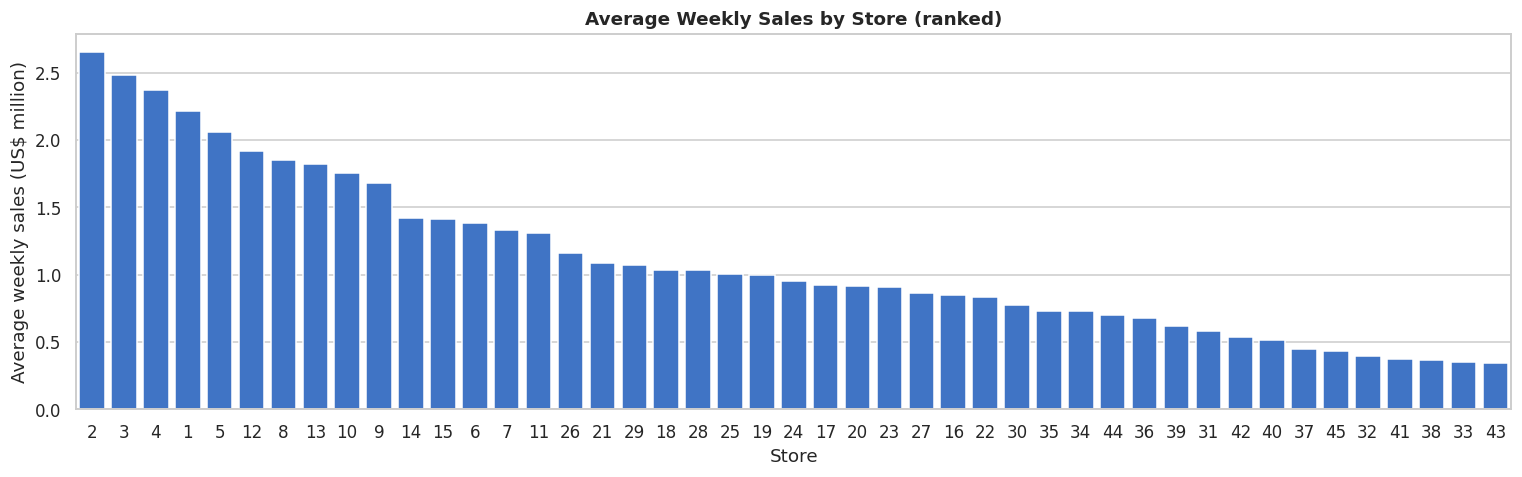

In [15]:
order = store_stats.index
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.barplot(x=store_stats.loc[order].index.astype(str), y=store_stats.loc[order,'mean']/1e6, color='#2a6fdb', ax=ax)
ax.set(title='Average Weekly Sales by Store (ranked)', xlabel='Store', ylabel='Average weekly sales (US$ million)')
savefig('02_store_avg_sales.png')

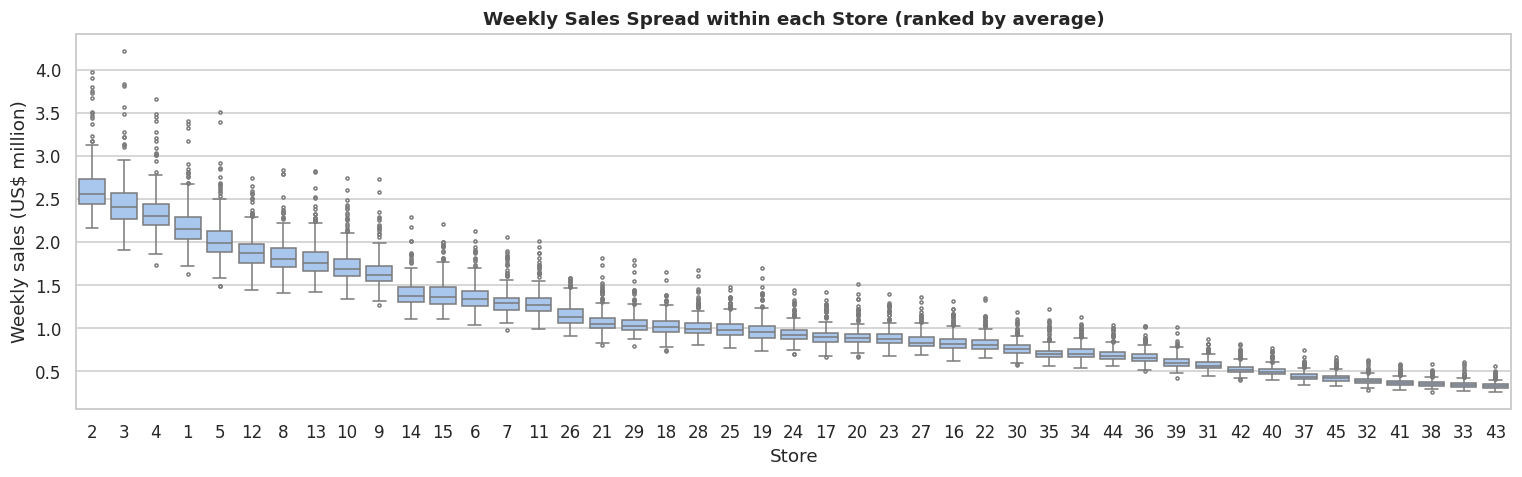

In [16]:
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.boxplot(data=df, x='Store', y=df['Weekly_Sales']/1e6, order=order, color='#9ec5f8', fliersize=2, ax=ax)
ax.set(title='Weekly Sales Spread within each Store (ranked by average)', xlabel='Store', ylabel='Weekly sales (US$ million)')
savefig('03_store_boxplot.png')

**Insight:** the ranked bar chart shows a steady step down from large to small stores. The top 10 stores (Store 2 down to Store 9) sit at roughly US$1.7–2.7 M per week, then there is a visible drop to about US$1.4 M, and the smallest stores sit below US$0.5 M. The box plots show each store's weekly sales stay within a fairly consistent band, with upper dots (peak weeks) for most stores.

### 5.3 Sales over time

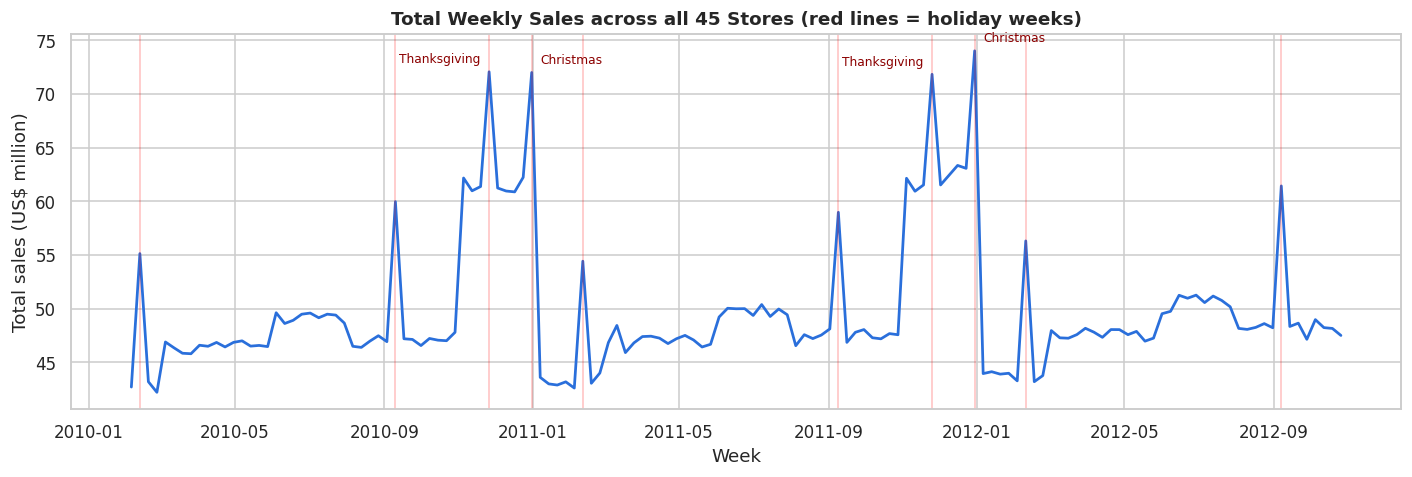

In [17]:
total = df.groupby('Date')['Weekly_Sales'].sum() / 1e6
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(total.index, total.values, color='#2a6fdb', lw=1.8)
for d, name in lookup.items():
    if d in total.index:
        ax.axvline(d, color='red', alpha=.25, lw=1)
        if name in ('Thanksgiving', 'Christmas'):
            ax.annotate(name, (d, total[d]), textcoords='offset points',
                        xytext=(-6, 6) if name == 'Thanksgiving' else (6, 6),
                        ha='right' if name == 'Thanksgiving' else 'left', fontsize=8, color='darkred')
ax.set(title='Total Weekly Sales across all 45 Stores (red lines = holiday weeks)', xlabel='Week', ylabel='Total sales (US$ million)')
savefig('04_total_sales_timeseries.png')

**Insight:** the chain-wide pattern repeats each year: a calm level of roughly US$45–50 M/week, small bumps around Super Bowl and Labor Day, and two big spikes (≈ US$72–74 M) in the **Thanksgiving week and the last week of December**. After the year-end peak sales fall back to the lowest levels of the year. Because the pattern repeats almost identically in 2010 and 2011, "same week last year" is a strong forecasting clue (used in Section 6).

### 5.4 Seasonality and holiday effect

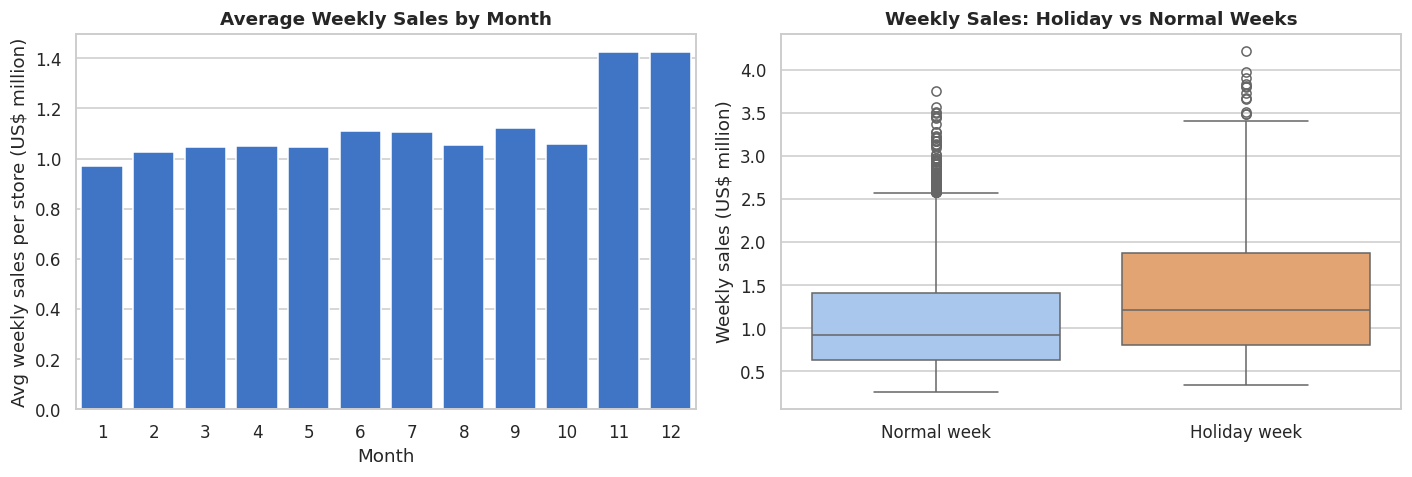

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
# Seasonality: average sales per store-week for each calendar month (2010-2012 mixed; 2012 has no Nov-Dec)
monthly = df.groupby('Month')['Weekly_Sales'].mean()/1e6
sns.barplot(x=monthly.index, y=monthly.values, color='#2a6fdb', ax=ax[0])
ax[0].set(title='Average Weekly Sales by Month', xlabel='Month', ylabel='Avg weekly sales per store (US$ million)')
# Holiday vs normal
sns.boxplot(data=df, x=df['Holiday_Flag'].map({0:'Normal week',1:'Holiday week'}), y=df['Weekly_Sales']/1e6, palette=['#9ec5f8','#f4a261'], ax=ax[1])
ax[1].set(title='Weekly Sales: Holiday vs Normal Weeks', xlabel='', ylabel='Weekly sales (US$ million)')
savefig('05_seasonality_holiday.png')

,mean,count
Holiday_Name,,
Christmas,1.467,90
Thanksgiving,1.441,90
Labor Day,1.209,135
Super Bowl,1.103,135
None,0.979,5985


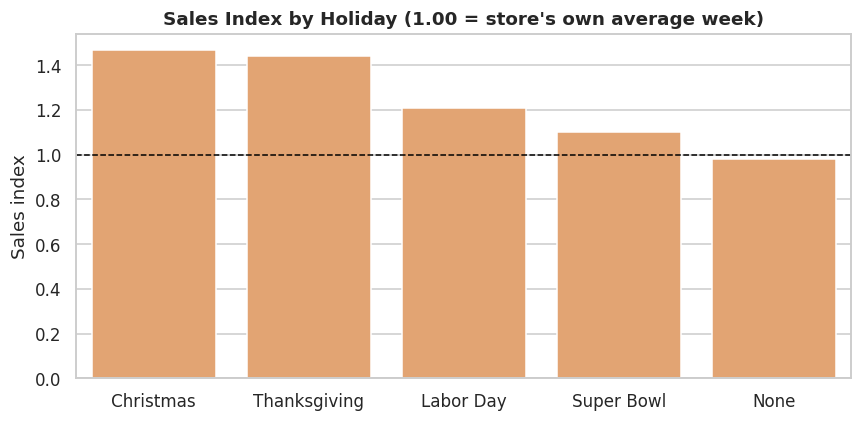

In [19]:
# Fair holiday comparison: each week vs that STORE's own average (index 1.00 = normal)
df['Sales_Index'] = df['Weekly_Sales'] / df.groupby('Store')['Weekly_Sales'].transform('mean')
idx = df.groupby('Holiday_Name')['Sales_Index'].agg(['mean','count']).sort_values('mean', ascending=False)
display(idx.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=idx.index, y=idx['mean'], color='#f4a261', ax=ax)
ax.axhline(1, color='black', ls='--', lw=1)
ax.set(title='Sales Index by Holiday (1.00 = store\'s own average week)', xlabel='', ylabel='Sales index')
savefig('06_holiday_index.png')

In [20]:
# Is the holiday difference real or just luck?  Simple permutation test on the Sales_Index
rng = np.random.default_rng(RANDOM_STATE)
hol = df.loc[df['Holiday_Flag']==1, 'Sales_Index'].values
nor = df.loc[df['Holiday_Flag']==0, 'Sales_Index'].values
obs = hol.mean() - nor.mean()
pool = np.concatenate([hol, nor]); n = len(hol)
perm = np.array([ (lambda p: p[:n].mean() - p[n:].mean())(rng.permutation(pool)) for _ in range(5000)])
print(f'Observed gap in sales index (holiday - normal): {obs:.4f}')
p = (np.abs(perm) >= abs(obs)).mean()
print('Permutation p-value (5000 shuffles)           :', f'{p:.4f}' if p > 0 else '< 0.0002 (no shuffle reached the observed gap)')

Observed gap in sales index (holiday - normal): 0.2957
Permutation p-value (5000 shuffles)           : < 0.0002 (no shuffle reached the observed gap)


**Insight**
- **Seasonality is clear:** November and December average about **1.43 M per store-week**, versus roughly 1.0–1.1 M in other months (January is the lowest, ≈ 0.97 M). Note that the data has no Nov–Dec for 2012, so those months come from 2010 and 2011 only.
- **Holiday weeks sell more, but not all alike.** Relative to each store's own average week (index 1.00): Christmas week **1.47**, Thanksgiving **1.44**, Labor Day **1.21**, Super Bowl **1.10**, normal weeks **0.98**.
- The gap between holiday and normal weeks (+0.30 in the index) is far larger than random shuffling produces (permutation p < 0.0002), so it is a real pattern, not luck.
- **A gap in the flag:** the week before Christmas (24 Dec 2010 and 23 Dec 2011) is *not* flagged as a holiday, yet its index is about **1.24–1.26**. `Holiday_Flag` therefore under-represents the Christmas rush, and a model should also use the calendar (month / week of year).

### 5.5 External factors vs sales

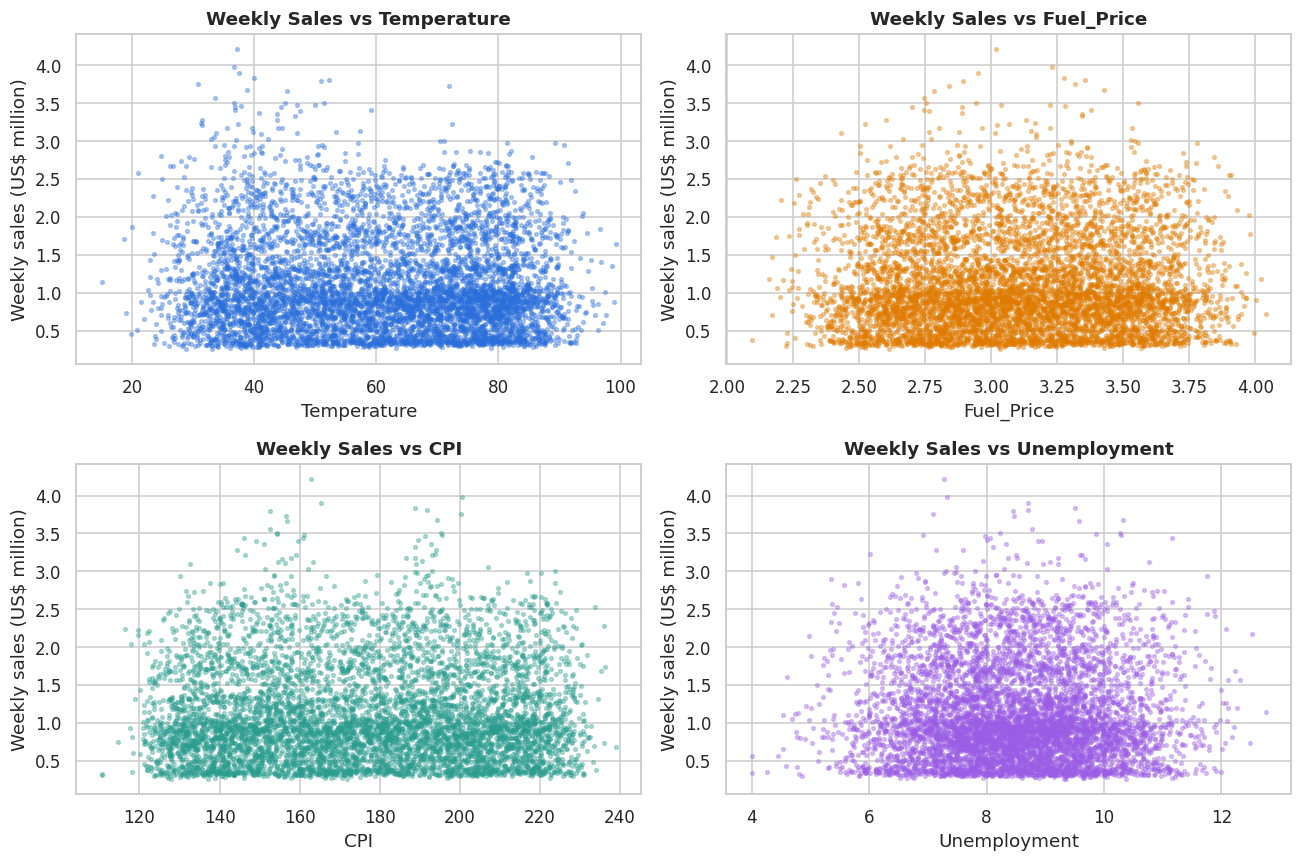

In [21]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for a, c, col in zip(ax.ravel(), ['Temperature','Fuel_Price','CPI','Unemployment'], ['#2a6fdb','#e07b00','#2a9d8f','#9b5de5']):
    a.scatter(df[c], df['Weekly_Sales']/1e6, s=6, alpha=.35, color=col)
    a.set(title=f'Weekly Sales vs {c}', xlabel=c, ylabel='Weekly sales (US$ million)')
savefig('07_scatter_external.png')

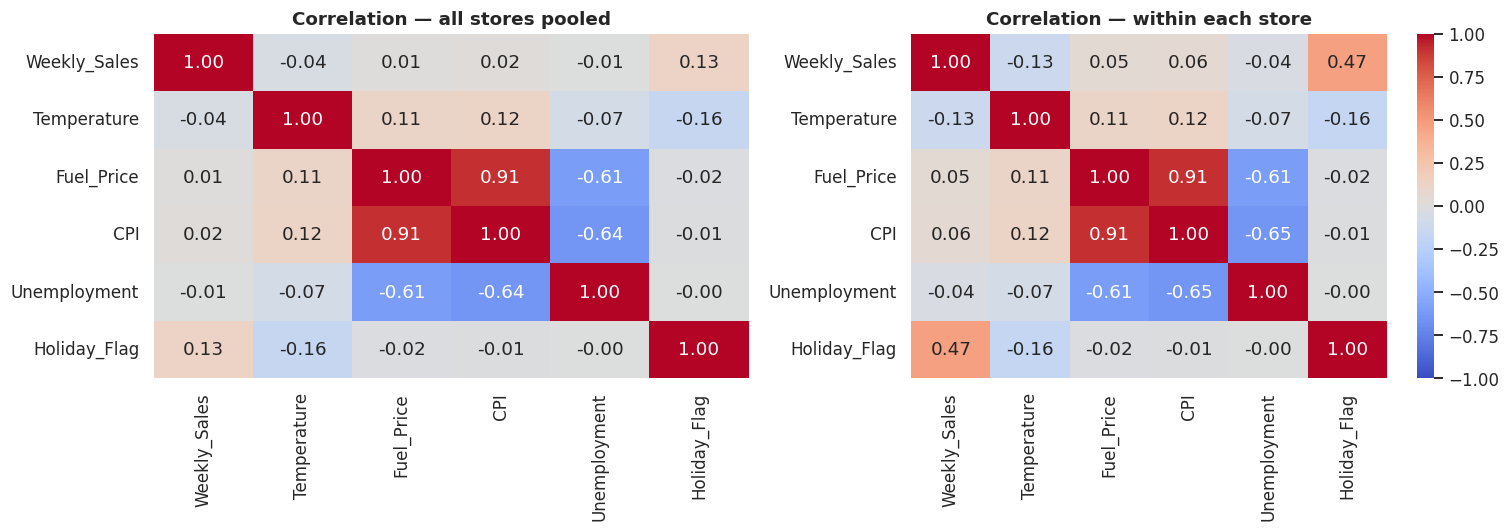

In [22]:
# Correlation: pooled across all stores vs. WITHIN each store.
# Pooled mixes 'big store vs small store' with real effects, so we also remove each store's own average.
cols = ['Weekly_Sales','Temperature','Fuel_Price','CPI','Unemployment','Holiday_Flag']
pooled = df[cols].corr()
within = (df[cols] - df.groupby('Store')[cols].transform('mean')).corr()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pooled, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax[0], cbar=False)
ax[0].set_title('Correlation — all stores pooled')
sns.heatmap(within, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title('Correlation — within each store')
savefig('08_correlation_heatmaps.png')

**Insight (correlation is not causation)**
- Pooled across all stores, sales have almost no linear relationship with temperature (−0.04), fuel price (0.01), CPI (0.02) or unemployment (−0.01). This does **not** prove they don't matter; store size swamps everything else.
- After removing each store's own average ("within each store"), the picture sharpens a little: Holiday_Flag **0.47**, Temperature **−0.13** (colder weeks sell more, which likely reflects the winter holiday season rather than cold weather itself), CPI 0.06, Fuel_Price 0.05, Unemployment −0.04.
- The economic variables are strongly linked to **each other** (Fuel_Price vs CPI 0.91; Unemployment vs CPI −0.64). That overlap would confuse a linear model, and they appear to move together over time, not independently.
- Weak correlation here means no *linear* link in this data; it says nothing about cause.

## 6. Feature Engineering and Predictive Modelling
**Task type:** regression — predict a store's `Weekly_Sales` for a week using what was known *before* that week.

**Features (all known in advance or from the past):**
- Store (one-hot), Holiday_Flag, Temperature, Fuel_Price, CPI, Unemployment
- Month and week of year (seasonality)
- `lag_1`: the same store's sales one week earlier
- `lag_52`: the same store's sales one year earlier (same week)
- `roll_mean_4`: average of the previous 4 weeks (shifted, so it never includes the current week)

**Avoiding data leakage:** lags and rolling averages are built *within each store* and shifted so only the past is used. The split is **by time** (first ~80 % of weeks train, the last weeks test); we never shuffle, because shuffling would let the model peek at the future.

In [23]:
m = df.sort_values(['Store','Date']).copy()
g = m.groupby('Store')['Weekly_Sales']
m['lag_1']       = g.shift(1)
m['lag_52']      = g.shift(52)
m['roll_mean_4'] = g.transform(lambda s: s.shift(1).rolling(4).mean())
m = m.dropna(subset=['lag_1','lag_52','roll_mean_4']).reset_index(drop=True)

cut = m['Date'].drop_duplicates().sort_values().iloc[int(0.8 * m['Date'].nunique())]
train, test = m[m['Date'] < cut], m[m['Date'] >= cut]
print(f'Rows after building lags : {len(m)}')
print(f'Train: {train["Date"].min().date()} -> {train["Date"].max().date()}  ({len(train)} rows)')
print(f'Test : {test["Date"].min().date()} -> {test["Date"].max().date()}  ({len(test)} rows)')

Rows after building lags : 4095
Train: 2011-02-04 -> 2012-06-15  (3240 rows)
Test : 2012-06-22 -> 2012-10-26  (855 rows)


In [24]:
num_f = ['Holiday_Flag','Temperature','Fuel_Price','CPI','Unemployment','Month','WeekOfYear','lag_1','lag_52','roll_mean_4']
cat_f = ['Store']
X_tr, y_tr = train[num_f + cat_f], train['Weekly_Sales']
X_te, y_te = test[num_f + cat_f],  test['Weekly_Sales']

def make_pipe(model, scale):
    pre = ColumnTransformer([
        ('num', StandardScaler() if scale else 'passthrough', num_f),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_f)])
    return Pipeline([('pre', pre), ('model', model)])

def score(name, y_true, y_pred):
    return {'Model': name,
            'MAE' : mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2'  : r2_score(y_true, y_pred),
            'MAPE %': 100*np.mean(np.abs((y_true-y_pred)/y_true))}

results = [score('Naive: same as last week', y_te, test['lag_1']),
           score('Naive: same week last year', y_te, test['lag_52'])]

lin = make_pipe(LinearRegression(), scale=True).fit(X_tr, y_tr)
rf  = make_pipe(RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1), scale=False).fit(X_tr, y_tr)
pred_lin, pred_rf = lin.predict(X_te), rf.predict(X_te)
results += [score('Linear Regression', y_te, pred_lin), score('Random Forest', y_te, pred_rf)]

res = pd.DataFrame(results).set_index('Model')
res.round(3)

,MAE,RMSE,R2,MAPE %
Model,,,,
Naive: same as last week,91423.096,144038.465,0.945,8.419
Naive: same week last year,75415.632,106155.611,0.970,6.811
Linear Regression,67352.812,92171.806,0.978,6.676
Random Forest,64897.017,94074.022,0.977,5.928


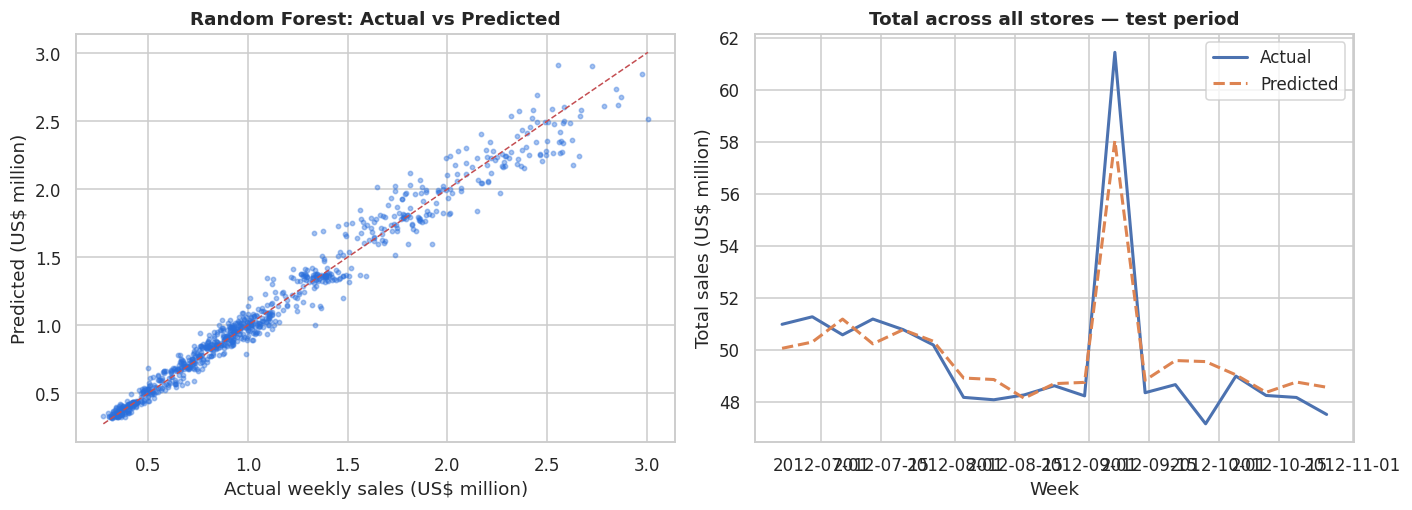

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].scatter(y_te/1e6, pred_rf/1e6, s=8, alpha=.4, color='#2a6fdb')
lim = [y_te.min()/1e6, y_te.max()/1e6]
ax[0].plot(lim, lim, 'r--', lw=1)
ax[0].set(title='Random Forest: Actual vs Predicted', xlabel='Actual weekly sales (US$ million)', ylabel='Predicted (US$ million)')

# Chain-wide view on test weeks
t = test.assign(pred=pred_rf).groupby('Date')[['Weekly_Sales','pred']].sum()/1e6
ax[1].plot(t.index, t['Weekly_Sales'], label='Actual', lw=2)
ax[1].plot(t.index, t['pred'], label='Predicted', lw=2, ls='--')
ax[1].set(title='Total across all stores — test period', xlabel='Week', ylabel='Total sales (US$ million)'); ax[1].legend()
savefig('09_model_actual_vs_pred.png')

Random Forest error by week type:


,abs_err,pct_err
Holiday_Flag,,
Holiday,117038.4,8.3
Normal,62000.3,5.8


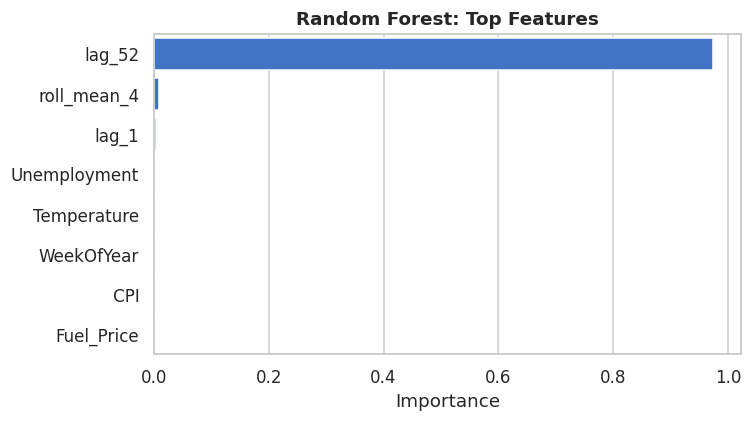

In [26]:
# Where does the model struggle?  Error on holiday vs normal weeks, and a feature-importance view
err = test.assign(abs_err=np.abs(y_te - pred_rf), pct_err=100*np.abs(y_te - pred_rf)/y_te)
print('Random Forest error by week type:')
display(err.groupby(err['Holiday_Flag'].map({0:'Normal',1:'Holiday'}))[['abs_err','pct_err']].mean().round(1))

names = rf.named_steps['pre'].get_feature_names_out()
imp = pd.Series(rf.named_steps['model'].feature_importances_, index=names)
imp.index = [i.replace('num__','').replace('cat__','') for i in imp.index]
top = imp.sort_values(ascending=False).head(8)
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=top.values, y=top.index, color='#2a6fdb', ax=ax)
ax.set(title='Random Forest: Top Features', xlabel='Importance', ylabel='')
savefig('10_feature_importance.png')
res.round(3).to_csv(os.path.join(OUT_DIR, 'model_metrics.csv'))
pd.DataFrame({'Store':test['Store'],'Date':test['Date'],'Actual':y_te,'Pred_RF':pred_rf,'Pred_Linear':pred_lin}).to_csv(os.path.join(OUT_DIR,'test_predictions.csv'), index=False)

**Reading the results (test period: 22 Jun – 26 Oct 2012)**

| Model | MAE (US$) | RMSE (US$) | R² | MAPE % |
|---|---|---|---|---|
| Naive: same as last week | 91,423 | 144,038 | 0.945 | 8.4 |
| Naive: same week last year | 75,416 | 106,156 | 0.970 | 6.8 |
| Linear Regression | 67,353 | 92,172 | 0.978 | 6.7 |
| Random Forest | 64,897 | 94,074 | 0.977 | 5.9 |

- Both machine-learning models beat both "common-sense" baselines. The Random Forest is off by about **US$65 k per store-week (≈ 5.9 %)**, about 14 % lower MAE than "same week last year". Linear Regression has a slightly lower RMSE, so the two are close; neither is clearly better.
- **Feature importance:** `lag_52` (same week last year) accounts for about **97 %** of the Random Forest's importance. Temperature, fuel price, CPI and unemployment add almost nothing. The model works by copying last year's pattern and adjusting it a little.
- **Errors are larger in holiday weeks** (average error about US$117 k, 8.3 %) than in normal weeks (about US$62 k, 5.8 %).

## 7. Interpretation, Limitations and Conclusion

**Key findings**
1. The data is clean and complete (45 stores × 143 weeks). Stores differ mainly in **size** (7.8× from largest to smallest), not in stability.
2. Sales are strongly **seasonal and holiday-driven**: Thanksgiving and Christmas weeks sell about 1.4–1.5× a store's normal week, Labor Day about 1.2×, Super Bowl about 1.1×. The pre-Christmas week is also strong but not flagged.
3. Temperature, fuel price, CPI and unemployment show **weak linear relationships** with sales. Fuel price, CPI and unemployment are themselves strongly related to each other.
4. High-sales "outliers" are real seasonal peaks and were kept.
5. A Random Forest that uses last year's same-week sales reaches **MAE ≈ US$65 k (≈ 5.9 %)** on unseen later weeks, better than naive baselines, but mostly because of that one feature.

**Business implications:** plan stock and staffing from each store's own last-year pattern, with extra attention to late November through December and the pre-Christmas week.

**Limitations**
- **The test period (Jun–Oct 2012) contains only one holiday week (Labor Day) and no Nov–Dec**, so performance during the biggest peaks is *not* tested. Holiday-week error (8.3 %) is already worse than normal weeks.
- Only ~2.7 years of data: yearly patterns are seen two to three times, and `lag_52` needs a full year of history (the first 52 weeks per store cannot be used for modelling).
- The forecast is one week ahead using actual past sales; forecasting many weeks ahead would be harder.
- No department, promotion, store size/type or competitor data; the model cannot explain *why* sales move, only that they do.
- Correlations describe association only, not cause.

**Possible improvements:** add promotion/markdown data and store attributes; time-series cross-validation with several test windows; tune the Random Forest; try gradient boosting or a dedicated seasonal forecasting model; add a "week before Christmas" feature.

**References**
- Walmart sales dataset, Kaggle (derived from the Walmart Recruiting — Store Sales Forecasting competition data).
- pandas, Matplotlib, Seaborn and scikit-learn documentation.